## Ćwiczenie 7: Zadanie Samodzielne - ROZWIĄZANIA

Twoim zadaniem jest stworzenie pełnego procesu segmentacyjnego dla pojedynczego przekroju z bazy danych z wykorzystaniem progowania Otsu i operacji morfologicznych. Na koniec oblicz faktyczne fizyczne pole powierzchni wyizolowanej struktury.

### Krok 1: Wczytanie i przygotowanie sztucznego zestawu danych (Mock DICOM)
Aby ułatwić zadanie bez konieczności pobierania plików .dcm, użyjemy wbudowany obraz oraz zasymulujemy odczyt atrybutu `PixelSpacing`.

C:\ProgramData\anaconda3\Lib\site-packages\paramiko\pkey.py:82: CryptographyDeprecationWarning: TripleDES has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.TripleDES and will be removed from this module in 48.0.0.
  "cipher": algorithms.TripleDES,
C:\ProgramData\anaconda3\Lib\site-packages\paramiko\transport.py:219: CryptographyDeprecationWarning: Blowfish has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.Blowfish and will be removed from this module in 45.0.0.
  "class": algorithms.Blowfish,
C:\ProgramData\anaconda3\Lib\site-packages\paramiko\transport.py:243: CryptographyDeprecationWarning: TripleDES has been moved to cryptography.hazmat.decrepit.ciphers.algorithms.TripleDES and will be removed from this module in 48.0.0.
  "class": algorithms.TripleDES,


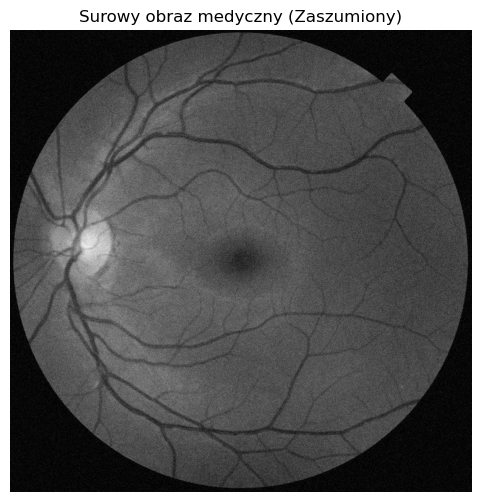

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, filters, morphology, util, measure
from scipy import ndimage

# --- Symulacja środowiska klinicznego ---
# 1. Pobieramy wbudowany obraz siatkówki oka jako nasz "przypadek medyczny"
retina = data.retina()
image_medical = retina[:, :, 1] # kanał czerwony dla dużego kontrastu naczyń
image_medical = util.random_noise(image_medical, mode='gaussian', var=0.005) # Dodajemy szum sprzętowy

# 2. Symulujemy odczyt z nagłówka DICOM (tag 0028, 0030)
dicom_pixel_spacing_x = 0.08  # mm / pixel
dicom_pixel_spacing_y = 0.08  # mm / pixel

plt.figure(figsize=(6,6))
plt.imshow(image_medical, cmap='gray')
plt.title('Surowy obraz medyczny (Zaszumiony)')
plt.axis('off')
plt.show()

### Krok 2: Binaryzacja Otsu

**Twoje zadanie:**
1. Zastosuj wygładzanie obrazu filtrem Gaussa (`filters.gaussian`), aby nieco zredukować szum sprzętowy.
2. Znajdź optymalny próg jasności za pomocą metody Otsu (`filters.threshold_otsu`).
3. Utwórz surową maskę binarną. **Uwaga:** Interesują nas ciemne obszary (naczynia)! Upewnij się, że znak nierówności wybierze piksele *ciemniejsze* od progu.

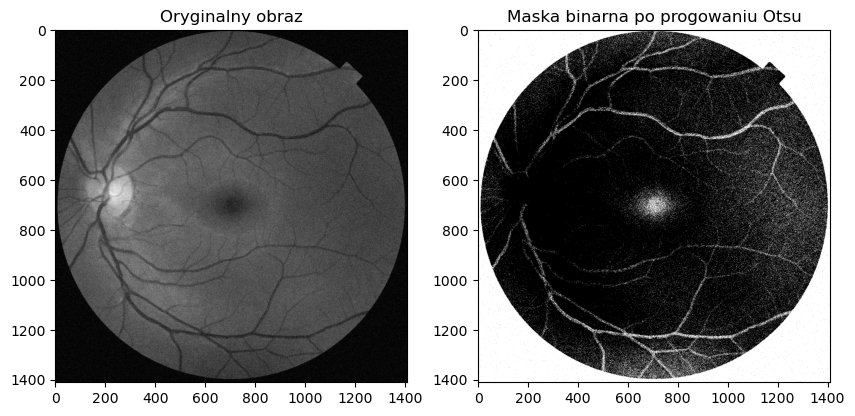

In [18]:
# Zastosowanie metody progowania Otsu
thresh = filters.threshold_otsu(image_medical)
binary_mask = image_medical < thresh

# Wizualizacja oryginalnego obrazu oraz maski
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.title('Oryginalny obraz')
plt.imshow(image_medical, cmap='gray')
plt.subplot(1, 2, 2)
plt.title('Maska binarna po progowaniu Otsu')
plt.imshow(binary_mask, cmap='gray')
plt.show()

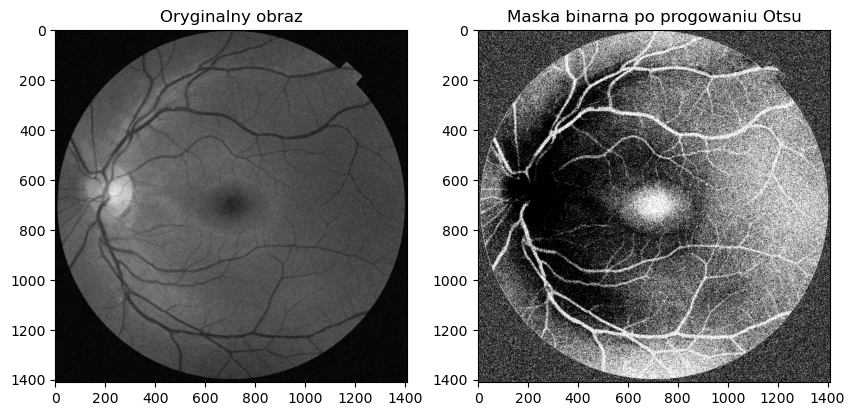

In [22]:
# Zastosowanie metody progowania Otsu + maska
# Wyznaczenie maski wnętrza oka (odrzucamy czarne tło wokół okręgu)
valid_mask = image_medical > 0.05


thresh = filters.threshold_otsu(image_medical[valid_mask])
binary_vessels = (image_medical < thresh) & valid_mask

# Wizualizacja oryginalnego obrazu oraz maski
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.title('Oryginalny obraz')
plt.imshow(image_medical, cmap='gray')
plt.subplot(1, 2, 2)
plt.title('Maska binarna po progowaniu Otsu')
plt.imshow(binary_vessels, cmap='gray')
plt.show()

### Krok 3: Naprawa morfologiczna

Prawdopodobnie Twoja maska zawiera mnóstwo białego szumu (pojedynczych pikseli w tle). 

**Twoje zadanie:**
Zastosuj operację **Otwarcia** (Opening), aby usunąć te artefakty, pozostawiając tylko główną sieć narządów. Dobierz odpowiedni rozmiar elementu strukturalnego (`morphology.disk(r)`), tak aby szum zniknął, ale główne odgałęzienia nie zostały całkowicie wymazane.

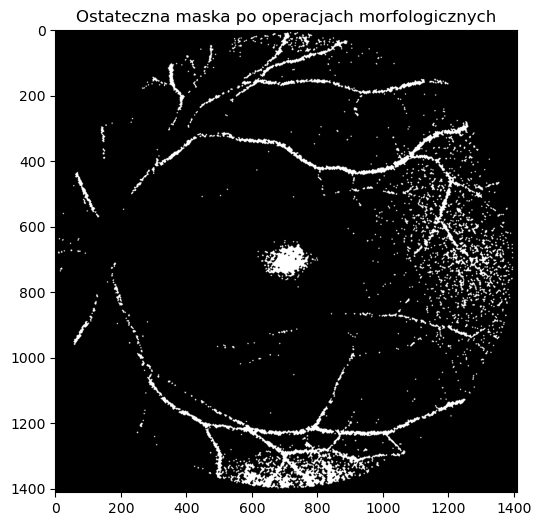

In [12]:
# TUTAJ WPISZ SWÓJ KOD
selem = morphology.disk(2)

#Operacja otwarcia (usuwa drobny szum tła i pojedyncze piksele)
cleaned_mask = morphology.opening(binary_vessels, selem)

#Operacja zamknięcia (skleja ewentualne przerwy w ciągłości naczyń)
cleaned_mask = morphology.closing(cleaned_mask, selem)

#Dodatkowe usunięcie zbyt małych obiektów (wszystko mniejsze niż np. 50 pikseli zniknie)
#cleaned_mask = morphology.remove_small_objects(cleaned_mask, min_size=50)

# Do weryfikacji wizualnej:
plt.figure(figsize=(6, 6))
plt.title('Ostateczna maska po operacjach morfologicznych')
plt.imshow(cleaned_mask, cmap='gray')
plt.show()

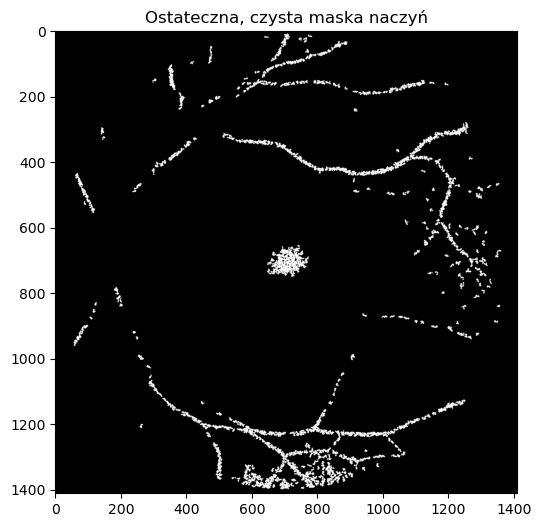

In [14]:
# Zwiększenie promienia dysku strukturalnego (np. z 2 na 3), co mocniej potraktuje drobne punkty szumu
selem = morphology.disk(2)
opened_mask = morphology.opening(binary_vessels, selem)

#Operacja zamknięcia (skleja ewentualne przerwy w ciągłości naczyń)
cleaned_mask = morphology.closing(cleaned_mask, selem)

#Zwiększenie min_size w funkcji usuwania małych obiektów
#Wartość 200 oznacza, że każdy oderwany fragment mniejszy niż 200 pikseli zostanie usunięty
cleaned_mask = morphology.remove_small_objects(opened_mask, min_size=50)

#Wizualizacja poprawionej maski
plt.figure(figsize=(6, 6))
plt.title('Ostateczna, czysta maska naczyń')
plt.imshow(cleaned_mask, cmap='gray')
plt.show()

### Krok 4: Analityka i Fizyczne Pole Powierzchni (Kluczowy krok dla DICOM)

Radiolog nie wie, co to są piksele. Potrzebuje wyniku w milimetrach kwadratowych.

**Twoje zadanie:**
1. Oblicz ile pojedynczych pikseli składa się na Twoją `czysta_maska`.
2. Wykorzystaj zmienne `dicom_pixel_spacing_x` oraz `dicom_pixel_spacing_y` (podane w Kroku 1), aby wyliczyć pole powierzchni jednego piksela w $mm^2$.
3. Pomnóż wynik i wypisz końcowe fizyczne pole powierzchni sieci naczyniowej.
4. (Dla ambitnych) Stwórz kolorowy obrys maski używając `^` (XOR) i nałóż go na obraz oryginalny.

In [91]:
# Zliczenie pikseli struktury (wartości True w oczyszczonej masce)
pixel_count = np.sum(cleaned_mask)
pixel_area = dicom_pixel_spacing_x * dicom_pixel_spacing_y

# Obliczenie faktycznego fizycznego pola powierzchni (pixel_area została zdefiniowana w Kroku 1)
physical_area = pixel_count * pixel_area

print(f'Liczba pikseli tworzących strukturę: {pixel_count}')
print(f'Fizyczne pole powierzchni wyizolowanej struktury: {physical_area:.2f} mm^2')

Liczba pikseli tworzących strukturę: 64138
Fizyczne pole powierzchni wyizolowanej struktury: 410.48 mm^2



### Dodatek 1: "Szkieletyzacja"

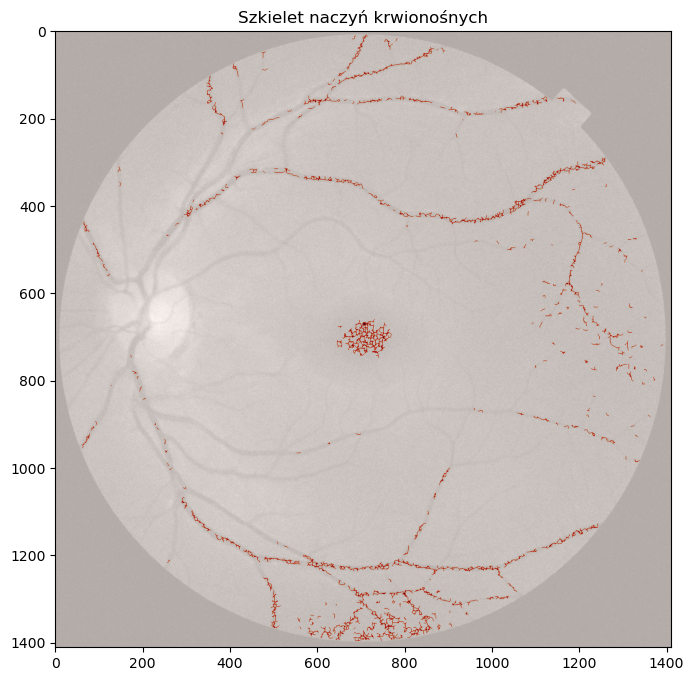

Całkowita szacowana długość naczyń: 7236.50 mm


In [105]:
# Szkieletyzacja (sprowadzenie naczyń do grubości 1 piksela)
skeleton = morphology.skeletonize(cleaned_mask)

# Wizualizacja nałożona na zielony kanał
plt.figure(figsize=(8, 8))
plt.title('Szkielet naczyń krwionośnych')
plt.imshow(image_medical, cmap='gray')
# Nakładamy szkielet na czerwono z przezroczystością
plt.imshow(skeleton, cmap='Reds', alpha=0.7)
plt.show()

# Opcjonalnie: całkowita długość naczyń to po prostu suma pikseli szkieletu
total_length = np.sum(skeleton) * 0.5  # przy założeniu piksela np. 0.5 mm
print(f"Całkowita szacowana długość naczyń: {total_length:.2f} mm")

### Dedykowany filtr medyczny (Frangi)

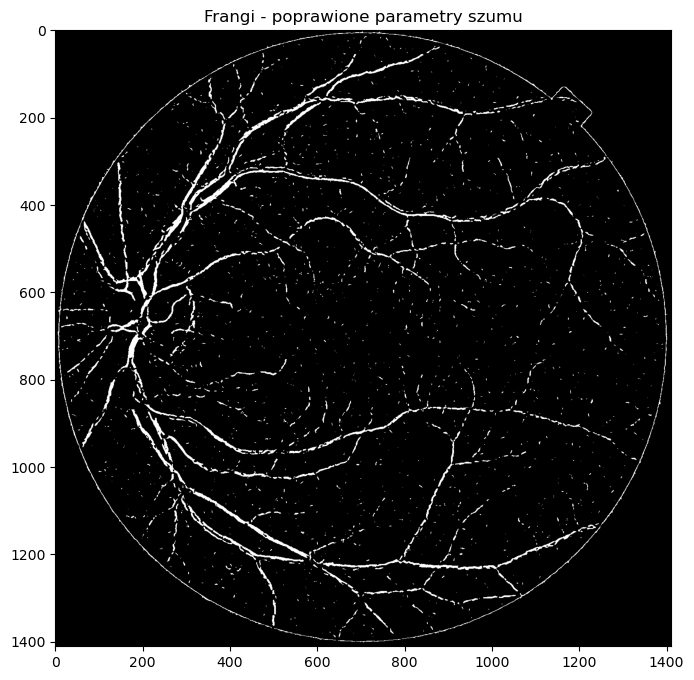

In [118]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.filters import frangi, gaussian

# 1. Upewnijmy się, że pracujemy na odpowiednim kanale (zielonym)
img_gray = image_medical[:, :, 1] if len(image_medical.shape) == 3 else image_medical

# 2. Delikatne rozmycie Gaussa zabija szum "śnieg", zanim Frangi go wykryje
img_blurred = gaussian(img_gray, sigma=1.5)

# 3. Maska wnętrza oka
valid_mask = img_blurred > 0.05

# 4. Filtr Frangiego z ręcznie ustawionym rozmiarem szukanych rurek (sigmas)
# Szukamy struktur o grubościach 2, 4, 6 i 8 pikseli
frangi_image = frangi(img_blurred, sigmas=range(2, 10, 2), black_ridges=True)

# Ignorujemy wszystko to, co wygenerowało się poza okiem (np. ostra krawędź tła)
frangi_image[~valid_mask] = 0

# 5. Progowanie (bierzemy 5% najsilniejszych wyników filtra)
thresh_frangi = np.percentile(frangi_image[valid_mask], 95)
frangi_mask = (frangi_image > thresh_frangi) & valid_mask

# 6. Wizualizacja ostateczna
plt.figure(figsize=(8, 8))
plt.title('Frangi - poprawione parametry szumu')
plt.imshow(frangi_mask, cmap='gray')
plt.show()